# Model comparison

All models are evaluated with the same cleaning, the same split (`test_size=0.2`, `random_state=42`, stratified) and the same 5-fold cross-validation on the training set. Metrics are read from each model's `metrics.json`.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid')
rows = [json.loads(p.read_text(encoding='utf-8')) for p in sorted(Path('.').glob('*/metrics.json'))]
table = pd.DataFrame(rows).set_index('model').round(3)
table

,cv_roc_auc_mean,cv_roc_auc_std,cv_f1_mean,cv_accuracy_mean,test_accuracy,test_f1,test_roc_auc
model,,,,,,,
CatBoost,0.853,0.033,0.822,0.798,0.821,0.845,0.888
Logistic Regression,0.873,0.023,0.816,0.792,0.804,0.829,0.898
Random Forest,0.860,0.027,0.819,0.796,0.810,0.837,0.899


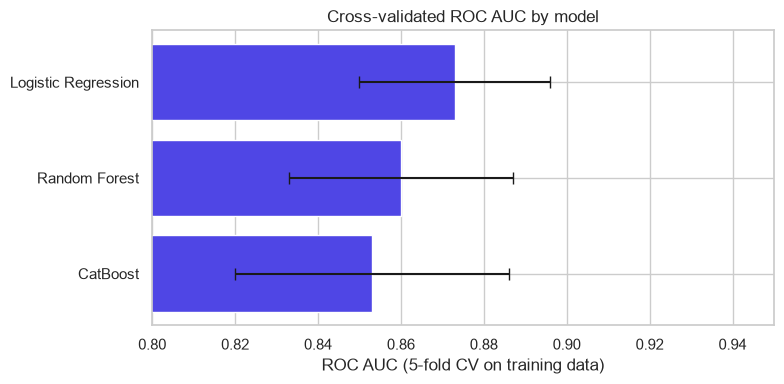

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
order = table.sort_values('cv_roc_auc_mean').index
ax.barh(order, table.loc[order, 'cv_roc_auc_mean'], xerr=table.loc[order, 'cv_roc_auc_std'],
        color='#4f46e5', capsize=4)
ax.set_xlim(0.8, 0.95)
ax.set_xlabel('ROC AUC (5-fold CV on training data)')
ax.set_title('Cross-validated ROC AUC by model')
plt.tight_layout()
plt.show()